In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image 
from collections import OrderedDict 
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm 
import torch
import timm
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, models
from torchvision.transforms import v2
import random
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import seaborn as sns
import torch.nn.functional as F
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from torch.utils.data import Subset, DataLoader
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix, classification_report, roc_curve, auc, roc_auc_score)
from imblearn.metrics import sensitivity_score, specificity_score

d:\Practise\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset_dir = Path(r"D:\GG\Datasets\Eye Disease Image Dataset\Fourier_Enhanced_Dataset")
image_height = 224
image_width = 224
batch_size = 32
base_learning_rate = 0.0001
epochs = 10
early_stopping_patience = 5
num_workers = os.cpu_count() // 2 if os.cpu_count() else 1 

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using {device} device")



# Augmentation
train_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.uint8, scale=True),
    v2.RandomResizedCrop(size=(image_height, image_width), 
                         scale=(0.8, 1.0), ratio=(0.9, 1.1), antialias=True),
    v2.RandomRotation(degrees=15, interpolation=v2.InterpolationMode.BILINEAR, fill=0), 
    v2.RandomHorizontalFlip(p=0.5),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
    v2.RandomAdjustSharpness(sharpness_factor=2, p=0.5),
    
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_test_transforms = v2.Compose([
    v2.ToImage(),
    v2.Resize((image_height, image_width), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])




temp_dataset = datasets.ImageFolder(root=dataset_dir)
targets = [s[1] for s in temp_dataset.samples]
dataset_indices = np.arange(len(targets))
class_names = temp_dataset.classes
number_of_classes = len(class_names)
targets = [s[1] for s in temp_dataset.samples]
print(f"Classes: {class_names}")



sss = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
dev_indices, test_indices = next(sss.split(dataset_indices, targets))


print(f"Total Data: {len(targets)}")
print(f"K-Fold Development Data: {len(dev_indices)}")
print(f"Hold-Out Test Data: {len(test_indices)}")


train_dataset_source = datasets.ImageFolder(root=dataset_dir, transform=train_transforms)
val_test_dataset_source = datasets.ImageFolder(root=dataset_dir, transform=val_test_transforms)


test_dataset = Subset(val_test_dataset_source, test_indices)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=num_workers)


k_folds = 5
kfold = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)


dev_targets = [targets[i] for i in dev_indices]


fold_results = []




for fold, (fold_train_idx_rel, fold_val_idx_rel) in enumerate(kfold.split(dev_indices, dev_targets)):
    

    
    # Map relative indices back to original dataset indices
    train_indices = dev_indices[fold_train_idx_rel]
    val_indices = dev_indices[fold_val_idx_rel]
    
    # Dynamic Class Weights (Calculated per fold) ---
    fold_train_targets = [targets[i] for i in train_indices]
    class_weights_arr = compute_class_weight('balanced', classes=np.unique(fold_train_targets), y=fold_train_targets)
    class_weights = torch.tensor(class_weights_arr, dtype=torch.float).to(device)
    
 
    # Train subset uses train_transforms
    train_subset = Subset(train_dataset_source, train_indices)
    # Val subset uses val_test_transforms
    val_subset = Subset(val_test_dataset_source, val_indices)
    

    train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)
    



Using cuda device
Classes: ['Color Fundus', 'Diabetic Retinopathy', 'Disc Edema', 'Glaucoma', 'Healthy', 'Macular Scar', 'Myopia', 'Pterygium', 'Retinal Detachment', 'Retinitis Pigmentosa']
Total Data: 16242
K-Fold Development Data: 13805
Hold-Out Test Data: 2437


## Models

In [3]:
efficient_model = models.efficientnet_b0(weights=None)
print(efficient_model)

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [5]:
vgg16_model = models.vgg16(weights=None)
print(vgg16_model)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [7]:
vit = timm.create_model('vit_base_patch16_224', pretrained=False)
print(vit)

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

### EfficinetNetB0 trained with freezed layers

In [21]:
efficientNetB0 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
for param in efficientNetB0.features.parameters():
    param.requires_grad = False


num_filters = efficientNetB0.classifier[1].in_features
efficientNetB0.classifier[1] = nn.Linear(num_filters, number_of_classes)
efficientNetB0 = efficientNetB0.to(device)
# print("Model details")
# print(efficientNetB0)


criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, efficientNetB0.parameters()), lr = base_learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)



best_val_loss = float('inf') 
best_val_acc = 0
patience_counter = 0
save_path_efficient = 'efficientNetB0_freezed.pth'
train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    #training the efficientNetB0
    efficientNetB0.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = efficientNetB0(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)


    train_acc = correct / total
    train_loss = running_loss / total
    train_acc_list.append(train_acc)
    train_loss_list.append(train_loss)

    #evaluation
    efficientNetB0.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = efficientNetB0(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)



        val_acc = val_correct / val_total
        val_loss /= val_total
        val_acc_list.append(val_acc)
        val_loss_list.append(val_loss)


        if val_acc > best_val_acc:
            best_val_acc = val_acc


        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save({
            'epoch': epoch + 1,
            'model_state_dict': efficientNetB0.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_val_loss,
            'accuracy': val_acc,          
            'best_accuracy': best_val_acc 
            }, save_path_efficient)
            print(f"Saved best model (Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"No improvement. EarlyStopping counter: {patience_counter}/{early_stopping_patience}")
            if patience_counter >= early_stopping_patience:
                print("Early stopping triggered.")
                break



Epoch 1/10


Epoch 1 validation: 100%|██████████| 87/87 [01:14<00:00,  1.17it/s]


Train Loss: 1.9604, Train Acc: 0.3670
Val Loss: 1.6701, Val Acc: 0.4929
Saved best model (Loss: 1.6701)

Epoch 2/10


Epoch 2 validation: 100%|██████████| 87/87 [01:09<00:00,  1.26it/s]


Train Loss: 1.5531, Train Acc: 0.5071
Val Loss: 1.4172, Val Acc: 0.4987
Saved best model (Loss: 1.4172)

Epoch 3/10


Epoch 3 validation: 100%|██████████| 87/87 [01:07<00:00,  1.28it/s]


... (11 outputs left out)

Epoch 9 validation: 100%|██████████| 87/87 [01:07<00:00,  1.30it/s]


Train Loss: 1.0288, Train Acc: 0.6009
Val Loss: 0.9981, Val Acc: 0.5683
Saved best model (Loss: 0.9981)

Epoch 10/10


Epoch 10 validation: 100%|██████████| 87/87 [01:07<00:00,  1.30it/s]

Train Loss: 1.0015, Train Acc: 0.6067
Val Loss: 0.9759, Val Acc: 0.5936
Saved best model (Loss: 0.9759)


### VGG16 trained with freezed layers

In [4]:
vgg16_model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
for param in vgg16_model.features.parameters():
    param.requires_grad = False



num_features = vgg16_model.classifier[6].in_features
vgg16_model.classifier[6] = nn.Linear(num_features, number_of_classes) 
vgg16_model = vgg16_model.to(device)
print(f"Model {type(vgg16_model).__name__} initialized for {number_of_classes} global classes.")


criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, vgg16_model.parameters()), lr = base_learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)



best_val_loss = float('inf') 
best_val_acc = 0
patience_counter = 0
save_path_vgg16 = 'vgg16_freezed.pth'
train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    #training the vgg16_model
    vgg16_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = vgg16_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)


    train_acc = correct / total
    train_loss = running_loss / total
    train_acc_list.append(train_acc)
    train_loss_list.append(train_loss)

    #evaluation
    vgg16_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = vgg16_model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)



        val_acc = val_correct / val_total
        val_loss /= val_total
        val_acc_list.append(val_acc)
        val_loss_list.append(val_loss)


        if val_acc > best_val_acc:
            best_val_acc = val_acc

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save({
            'epoch': epoch + 1,
            'model_state_dict': vgg16_model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_val_loss,
            'accuracy': val_acc,          
            'best_accuracy': best_val_acc 
            }, save_path_vgg16)
            print(f"Saved best model (Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"No improvement. EarlyStopping counter: {patience_counter}/{early_stopping_patience}")
            if patience_counter >= early_stopping_patience:
                print("Early stopping triggered.")
                break


Model VGG initialized for 10 global classes.

Epoch 1/10


Epoch 1 validation: 100%|██████████| 87/87 [01:03<00:00,  1.36it/s]


Train Loss: 1.2499, Train Acc: 0.4917
Val Loss: 0.9111, Val Acc: 0.5672
Saved best model (Loss: 0.9111)

Epoch 2/10


Epoch 2 validation: 100%|██████████| 87/87 [01:01<00:00,  1.41it/s]


Train Loss: 0.9035, Train Acc: 0.5968
Val Loss: 0.8474, Val Acc: 0.5864
Saved best model (Loss: 0.8474)

Epoch 3/10


Epoch 3 validation: 100%|██████████| 87/87 [01:03<00:00,  1.37it/s]


... (11 outputs left out)

Epoch 9 validation: 100%|██████████| 87/87 [01:04<00:00,  1.36it/s]


Train Loss: 0.5172, Train Acc: 0.7524
Val Loss: 0.5469, Val Acc: 0.7313
Saved best model (Loss: 0.5469)

Epoch 10/10


Epoch 10 validation: 100%|██████████| 87/87 [01:03<00:00,  1.37it/s]


Train Loss: 0.4953, Train Acc: 0.7592
Val Loss: 0.5176, Val Acc: 0.7490
Saved best model (Loss: 0.5176)


### Vision Transformer trained with freezed layers

In [5]:
vision_transformer = timm.create_model('vit_base_patch16_224', pretrained=True)


for param in vision_transformer.parameters():
    param.requires_grad = False

num_features = vision_transformer.head.in_features
vision_transformer.head = nn.Linear(num_features, number_of_classes)


vision_transformer = vision_transformer.to(device)
print(f"Model {type(vision_transformer).__name__} initialized for {number_of_classes} global classes.")

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, vision_transformer.parameters()), lr = base_learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)



best_val_loss = float('inf') 
best_val_acc = 0
patience_counter = 0
save_path_vit = 'vision_transformer_freezed.pth'
train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    #training the vision_transformer
    vision_transformer.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = vision_transformer(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)


    train_acc = correct / total
    train_loss = running_loss / total
    train_acc_list.append(train_acc)
    train_loss_list.append(train_loss)

    #evaluation
    vision_transformer.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = vision_transformer(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)



        val_acc = val_correct / val_total
        val_loss /= val_total
        val_acc_list.append(val_acc)
        val_loss_list.append(val_loss)


        if val_acc > best_val_acc:
            best_val_acc = val_acc

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save({
            'epoch': epoch + 1,
            'model_state_dict': vision_transformer.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_val_loss,
            'accuracy': val_acc,          
            'best_accuracy': best_val_acc 
            }, save_path_vit)
            print(f"Saved best model (Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"No improvement. EarlyStopping counter: {patience_counter}/{early_stopping_patience}")
            if patience_counter >= early_stopping_patience:
                print("Early stopping triggered.")
                break


Model VisionTransformer initialized for 10 global classes.

Epoch 1/10


Epoch 1 validation: 100%|██████████| 87/87 [01:02<00:00,  1.39it/s]


Train Loss: 1.7069, Train Acc: 0.3742
Val Loss: 1.3383, Val Acc: 0.5339
Saved best model (Loss: 1.3383)

Epoch 2/10


Epoch 2 validation: 100%|██████████| 87/87 [01:01<00:00,  1.43it/s]


Train Loss: 1.1910, Train Acc: 0.5595
Val Loss: 1.1235, Val Acc: 0.6099
Saved best model (Loss: 1.1235)

Epoch 3/10


Epoch 3 validation: 100%|██████████| 87/87 [01:00<00:00,  1.43it/s]


... (11 outputs left out)

Epoch 9 validation: 100%|██████████| 87/87 [00:54<00:00,  1.60it/s]


Train Loss: 0.7427, Train Acc: 0.7021
Val Loss: 0.7619, Val Acc: 0.6976
Saved best model (Loss: 0.7619)

Epoch 10/10


Epoch 10 validation: 100%|██████████| 87/87 [00:52<00:00,  1.67it/s]


Train Loss: 0.7213, Train Acc: 0.7030
Val Loss: 0.7545, Val Acc: 0.6947
Saved best model (Loss: 0.7545)


### EfficientNetB0 trained with last two unfreezed layer to see how it performs

In [3]:
efficientNetB0 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
for param in efficientNetB0.features.parameters():
    param.requires_grad = False
for param in efficientNetB0.features[7:].parameters():
    param.requires_grad = True

num_filters = efficientNetB0.classifier[1].in_features
efficientNetB0.classifier[1] = nn.Linear(num_filters, number_of_classes)
efficientNetB0 = efficientNetB0.to(device)
# print("Model details")
# print(efficientNetB0)


criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, efficientNetB0.parameters()), lr = base_learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)



best_val_loss = float('inf') 
best_val_acc = 0
patience_counter = 0
save_path_efficient = 'efficientNetB0_base.pth'
train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    #training the efficientNetB0
    efficientNetB0.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = efficientNetB0(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)


    train_acc = correct / total
    train_loss = running_loss / total
    train_acc_list.append(train_acc)
    train_loss_list.append(train_loss)

    #evaluation
    efficientNetB0.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = efficientNetB0(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)



        val_acc = val_correct / val_total
        val_loss /= val_total
        val_acc_list.append(val_acc)
        val_loss_list.append(val_loss)


        if val_acc > best_val_acc:
            best_val_acc = val_acc


        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save({
            'epoch': epoch + 1,
            'model_state_dict': efficientNetB0.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_val_loss,
            'accuracy': val_acc,          
            'best_accuracy': best_val_acc 
            }, save_path_efficient)
            print(f"Saved best model (Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"No improvement. EarlyStopping counter: {patience_counter}/{early_stopping_patience}")
            if patience_counter >= early_stopping_patience:
                print("Early stopping triggered.")
                break



Epoch 1/10


Epoch 1 validation: 100%|██████████| 87/87 [00:43<00:00,  2.00it/s]


Train Loss: 1.4379, Train Acc: 0.5045
Val Loss: 0.9351, Val Acc: 0.6117
Saved best model (Loss: 0.9351)

Epoch 2/10


Epoch 2 validation: 100%|██████████| 87/87 [00:36<00:00,  2.36it/s]


Train Loss: 0.8415, Train Acc: 0.6503
Val Loss: 0.6903, Val Acc: 0.6968
Saved best model (Loss: 0.6903)

Epoch 3/10


Epoch 3 validation: 100%|██████████| 87/87 [00:37<00:00,  2.35it/s]


... (11 outputs left out)

Epoch 9 validation: 100%|██████████| 87/87 [00:37<00:00,  2.35it/s]


Train Loss: 0.4009, Train Acc: 0.8042
Val Loss: 0.3989, Val Acc: 0.7899
Saved best model (Loss: 0.3989)

Epoch 10/10


Epoch 10 validation: 100%|██████████| 87/87 [00:36<00:00,  2.36it/s]

Train Loss: 0.3834, Train Acc: 0.8144
Val Loss: 0.3800, Val Acc: 0.7993
Saved best model (Loss: 0.3800)


### VGG16 trained with last six classifiers to see how it performs

In [4]:
vgg16_model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
for param in vgg16_model.features.parameters():
    param.requires_grad = False

for param in vgg16_model.features[24:].parameters():
    param.requires_grad = True

num_features = vgg16_model.classifier[6].in_features
vgg16_model.classifier[6] = nn.Linear(num_features, number_of_classes) 
vgg16_model = vgg16_model.to(device)
print(f"Model {type(vgg16_model).__name__} initialized for {number_of_classes} global classes.")


criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, vgg16_model.parameters()), lr = base_learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)



best_val_loss = float('inf') 
best_val_acc = 0
patience_counter = 0
save_path_vgg16 = 'vgg16_base.pth'
train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    #training the vgg16_model
    vgg16_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = vgg16_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)


    train_acc = correct / total
    train_loss = running_loss / total
    train_acc_list.append(train_acc)
    train_loss_list.append(train_loss)

    #evaluation
    vgg16_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = vgg16_model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)



        val_acc = val_correct / val_total
        val_loss /= val_total
        val_acc_list.append(val_acc)
        val_loss_list.append(val_loss)


        if val_acc > best_val_acc:
            best_val_acc = val_acc

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save({
            'epoch': epoch + 1,
            'model_state_dict': vgg16_model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_val_loss,
            'accuracy': val_acc,          
            'best_accuracy': best_val_acc 
            }, save_path_vgg16)
            print(f"Saved best model (Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"No improvement. EarlyStopping counter: {patience_counter}/{early_stopping_patience}")
            if patience_counter >= early_stopping_patience:
                print("Early stopping triggered.")
                break


Model VGG initialized for 10 global classes.

Epoch 1/10


Epoch 1 validation: 100%|██████████| 87/87 [00:37<00:00,  2.31it/s]


Train Loss: 0.9468, Train Acc: 0.6054
Val Loss: 0.6567, Val Acc: 0.6838
Saved best model (Loss: 0.6567)

Epoch 2/10


Epoch 2 validation: 100%|██████████| 87/87 [00:37<00:00,  2.33it/s]


Train Loss: 0.5105, Train Acc: 0.7621
Val Loss: 0.5474, Val Acc: 0.7486
Saved best model (Loss: 0.5474)

Epoch 3/10


Epoch 3 validation: 100%|██████████| 87/87 [00:37<00:00,  2.34it/s]


... (11 outputs left out)

Epoch 9 validation: 100%|██████████| 87/87 [00:37<00:00,  2.30it/s]


Train Loss: 0.2678, Train Acc: 0.8736
Val Loss: 0.3389, Val Acc: 0.8428
No improvement. EarlyStopping counter: 1/5

Epoch 10/10


Epoch 10 validation: 100%|██████████| 87/87 [00:38<00:00,  2.28it/s]


Train Loss: 0.2076, Train Acc: 0.8961
Val Loss: 0.2665, Val Acc: 0.8747
Saved best model (Loss: 0.2665)


### Vision Transformer trained with last block being unfreezed to see how it performs

In [3]:
vision_transformer = timm.create_model('vit_base_patch16_224', pretrained=True)


for param in vision_transformer.parameters():
    param.requires_grad = False

for param in vision_transformer.blocks[-1].parameters():
    param.requires_grad = True

num_features = vision_transformer.head.in_features
vision_transformer.head = nn.Linear(num_features, number_of_classes)


vision_transformer = vision_transformer.to(device)
print(f"Model {type(vision_transformer).__name__} initialized for {number_of_classes} global classes.")

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, vision_transformer.parameters()), lr = base_learning_rate)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)



best_val_loss = float('inf') 
best_val_acc = 0
patience_counter = 0
save_path_vit = 'vision_transformer_base.pth'
train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    #training the vision_transformer
    vision_transformer.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = vision_transformer(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)


    train_acc = correct / total
    train_loss = running_loss / total
    train_acc_list.append(train_acc)
    train_loss_list.append(train_loss)

    #evaluation
    vision_transformer.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = vision_transformer(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)



        val_acc = val_correct / val_total
        val_loss /= val_total
        val_acc_list.append(val_acc)
        val_loss_list.append(val_loss)


        if val_acc > best_val_acc:
            best_val_acc = val_acc

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            torch.save({
            'epoch': epoch + 1,
            'model_state_dict': vision_transformer.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_val_loss,
            'accuracy': val_acc,          
            'best_accuracy': best_val_acc 
            }, save_path_vit)
            print(f"Saved best model (Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            print(f"No improvement. EarlyStopping counter: {patience_counter}/{early_stopping_patience}")
            if patience_counter >= early_stopping_patience:
                print("Early stopping triggered.")
                break


Model VisionTransformer initialized for 10 global classes.

Epoch 1/10


Epoch 1 validation: 100%|██████████| 87/87 [01:12<00:00,  1.20it/s]


Train Loss: 0.9429, Train Acc: 0.6163
Val Loss: 0.6060, Val Acc: 0.7117
Saved best model (Loss: 0.6060)

Epoch 2/10


Epoch 2 validation: 100%|██████████| 87/87 [01:04<00:00,  1.35it/s]


Train Loss: 0.5107, Train Acc: 0.7652
Val Loss: 0.5071, Val Acc: 0.7566
Saved best model (Loss: 0.5071)

Epoch 3/10


Epoch 3 validation: 100%|██████████| 87/87 [01:09<00:00,  1.24it/s]


... (11 outputs left out)

Epoch 9 validation: 100%|██████████| 87/87 [01:01<00:00,  1.42it/s]


Train Loss: 0.2396, Train Acc: 0.8782
Val Loss: 0.3168, Val Acc: 0.8584
No improvement. EarlyStopping counter: 1/5

Epoch 10/10


Epoch 10 validation: 100%|██████████| 87/87 [01:01<00:00,  1.42it/s]


Train Loss: 0.2171, Train Acc: 0.8893
Val Loss: 0.2811, Val Acc: 0.8671
Saved best model (Loss: 0.2811)


### Attempting Ensemble with layer normalizatoin for ViT

In [6]:
class CustomEnsemble(nn.Module):
    def __init__(self, num_classes, path_eff, path_vgg, path_vit, device='cuda'):
        super(CustomEnsemble, self).__init__()
        
        # Loading EfficientNetB0 
        self.efficientNet = models.efficientnet_b0(weights=None)
        # recreating the exact structure used in training before loading weights
        eff_in_features = self.efficientNet.classifier[1].in_features
        self.efficientNet.classifier[1] = nn.Linear(eff_in_features, num_classes)
        
        
        checkpoint_eff = torch.load(path_eff, map_location=device)
        self.efficientNet.load_state_dict(checkpoint_eff['model_state_dict'])
        
        # Removing the head to output raw features 
        self.efficientNet.classifier = nn.Identity()
        
        # Loading VGG16
        self.vgg16 = models.vgg16(weights=None)
        
        vgg_in_features = self.vgg16.classifier[6].in_features
        self.vgg16.classifier[6] = nn.Linear(vgg_in_features, num_classes)
        
        
        checkpoint_vgg = torch.load(path_vgg, map_location=device)
        self.vgg16.load_state_dict(checkpoint_vgg['model_state_dict'])
        
        self.vgg16.classifier[6] = nn.Identity()

        # Loading Vision Transformer
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=False)
      
        vit_in_features = self.vit.head.in_features
        self.vit.head = nn.Linear(vit_in_features, num_classes)
        
       
        checkpoint_vit = torch.load(path_vit, map_location=device)
        self.vit.load_state_dict(checkpoint_vit['model_state_dict'])
        
    
        self.vit.head = nn.Identity()

        
        # freezing everything
        for model in [self.efficientNet, self.vgg16, self.vit]:
            for param in model.parameters():
                param.requires_grad = False
 
        # Unfreezing  last 2 blocks for eficientNet
        for param in self.efficientNet.features[7:].parameters():
            param.requires_grad = True

        # Unfreezing last 6 block of convulotions for vgg
        for param in self.vgg16.features[24:].parameters():
            param.requires_grad = True
            
        # Unfreezing the last block and then normalization of the layers
        for param in self.vit.blocks[-1].parameters():
            param.requires_grad = True
        for param in self.vit.norm.parameters():
            param.requires_grad = True

        # Custom Fusion Head
        total_features = eff_in_features + vgg_in_features + vit_in_features
        
        self.fusion_head = nn.Sequential(
            nn.Linear(total_features, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        f1 = self.efficientNet(x)
        f2 = self.vgg16(x)
        f3 = self.vit(x)
        
        concatenated_features = torch.cat((f1, f2, f3), dim=1)
        output = self.fusion_head(concatenated_features)
        return output


ensemble_model = CustomEnsemble(
    num_classes=number_of_classes,
    path_eff='efficientNetB0_freezed.pth', 
    path_vgg='vgg16_freezed.pth',
    path_vit='vision_transformer_freezed.pth',
    device=device
)

ensemble_model = ensemble_model.to(device)



# Separating the parameters into two groups
backbone_params = []
head_params = []

for name, param in ensemble_model.named_parameters():
    if not param.requires_grad:
        continue
        
    # If the parameter belongs to the new fusion head
    if "fusion_head" in name:
        head_params.append(param)
    # If it belongs to EfficientNet, VGG, or ViT
    else:
        backbone_params.append(param)

# using calculated class weights for imbalanced class
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam([
    {'params': backbone_params, 'lr': 1e-5}, 
    {'params': head_params, 'lr': 1e-4}      
], weight_decay=1e-3)


scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=4, min_lr=1e-7)


epochs = 50
best_val_loss = float('inf') 
best_val_acc = 0
patience_counter = 0
save_path_ensemble = 'custom_ensemble_model.pth' 

train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    
  
    ensemble_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} Training"): 
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = ensemble_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    train_loss_list.append(train_loss)
    train_acc_list.append(train_acc)

    # Validation
    ensemble_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} Validation"): 
            images, labels = images.to(device), labels.to(device)
            outputs = ensemble_model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total
    val_loss_list.append(val_loss)
    val_acc_list.append(val_acc)

   
    if val_acc > best_val_acc:
        best_val_acc = val_acc

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")


    scheduler.step(val_loss)


    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        
    
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': ensemble_model.state_dict(), 
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_val_loss,
            'accuracy': val_acc,          
            'best_accuracy': best_val_acc 
        }, save_path_ensemble)
        
        print(f"Saved best model (Loss: {best_val_loss:.4f})")
    else:
        patience_counter += 1
        print(f"No improvement. EarlyStopping counter: {patience_counter}/{early_stopping_patience}")
        if patience_counter >= early_stopping_patience:
            print("Early stopping triggered.")
            break


Epoch 1/50


Epoch 1 Validation: 100%|██████████| 87/87 [01:08<00:00,  1.28it/s]


Train Loss: 0.8035, Train Acc: 0.6892
Val Loss: 0.5070, Val Acc: 0.7787
Saved best model (Loss: 0.5070)

Epoch 2/50


Epoch 2 Validation: 100%|██████████| 87/87 [01:01<00:00,  1.42it/s]


Train Loss: 0.4353, Train Acc: 0.8071
Val Loss: 0.4235, Val Acc: 0.7950
Saved best model (Loss: 0.4235)

Epoch 3/50


Epoch 3 Validation: 100%|██████████| 87/87 [01:00<00:00,  1.44it/s]


... (53 outputs left out)

Epoch 30 Validation: 100%|██████████| 87/87 [00:59<00:00,  1.46it/s]


Train Loss: 0.1539, Train Acc: 0.9236
Val Loss: 0.2534, Val Acc: 0.8776
No improvement. EarlyStopping counter: 4/5

Epoch 31/50


Epoch 31 Validation: 100%|██████████| 87/87 [00:59<00:00,  1.46it/s]

Train Loss: 0.1538, Train Acc: 0.9199
Val Loss: 0.2547, Val Acc: 0.8769
No improvement. EarlyStopping counter: 5/5
Early stopping triggered.


## Final Model

In [ ]:
class CustomEnsemble(nn.Module):
    def __init__(self, num_classes, path_eff, path_vgg, path_vit, device='cuda'):
        super(CustomEnsemble, self).__init__()
        
        # Loading EfficientNetB0 
        self.efficientNet = models.efficientnet_b0(weights=None)
        # recreating the exact structure used in training before loading weights
        eff_in_features = self.efficientNet.classifier[1].in_features
        self.efficientNet.classifier[1] = nn.Linear(eff_in_features, num_classes)
        
        
        checkpoint_eff = torch.load(path_eff, map_location=device)
        self.efficientNet.load_state_dict(checkpoint_eff['model_state_dict'])
        
        # Removing the head to output raw features 
        self.efficientNet.classifier = nn.Identity()
        
        # Loading VGG16
        self.vgg16 = models.vgg16(weights=None)
        
        vgg_in_features = self.vgg16.classifier[6].in_features
        self.vgg16.classifier[6] = nn.Linear(vgg_in_features, num_classes)
        
        
        checkpoint_vgg = torch.load(path_vgg, map_location=device)
        self.vgg16.load_state_dict(checkpoint_vgg['model_state_dict'])
        
        self.vgg16.classifier[6] = nn.Identity()

        # Loading Vision Transformer
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=False)
      
        vit_in_features = self.vit.head.in_features
        self.vit.head = nn.Linear(vit_in_features, num_classes)
        
       
        checkpoint_vit = torch.load(path_vit, map_location=device)
        self.vit.load_state_dict(checkpoint_vit['model_state_dict'])
        
    
        self.vit.head = nn.Identity()

        
        # freezing everything
        for model in [self.efficientNet, self.vgg16, self.vit]:
            for param in model.parameters():
                param.requires_grad = False
 
        # Unfreezing  last 2 blocks for eficientNet
        for param in self.efficientNet.features[7:].parameters():
            param.requires_grad = True

        # Unfreezing last 6 block of convulotions for vgg
        for param in self.vgg16.features[24:].parameters():
            param.requires_grad = True
            
        # Unfreezing the last block and then normalization of the layers
        for param in self.vit.blocks[-1].parameters():
            param.requires_grad = True


        # Custom Fusion Head
        total_features = eff_in_features + vgg_in_features + vit_in_features
        
        self.fusion_head = nn.Sequential(
            nn.Linear(total_features, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        f1 = self.efficientNet(x)
        f2 = self.vgg16(x)
        f3 = self.vit(x)
        
        concatenated_features = torch.cat((f1, f2, f3), dim=1)
        output = self.fusion_head(concatenated_features)
        return output


ensemble_model = CustomEnsemble(
    num_classes=number_of_classes,
    path_eff='efficientNetB0_freezed.pth', 
    path_vgg='vgg16_freezed.pth',
    path_vit='vision_transformer_freezed.pth',
    device=device
)

ensemble_model = ensemble_model.to(device)



# Separating the parameters into two groups
backbone_params = []
head_params = []

for name, param in ensemble_model.named_parameters():
    if not param.requires_grad:
        continue
        
    # If the parameter belongs to the new fusion head
    if "fusion_head" in name:
        head_params.append(param)
    # If it belongs to EfficientNet, VGG, or ViT
    else:
        backbone_params.append(param)

# using calculated class weights for imbalanced class
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam([
    {'params': backbone_params, 'lr': 1e-5}, 
    {'params': head_params, 'lr': 1e-4}      
], weight_decay=1e-3)


scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=4, min_lr=1e-7)


epochs = 50
best_val_loss = float('inf') 
best_val_acc = 0
patience_counter = 0
save_path_ensemble = 'custom_ensemble_model_without_norm.pth' 

train_acc_list, val_acc_list = [], []
train_loss_list, val_loss_list = [], []

for epoch in range(epochs):
    print(f"\nEpoch {epoch+1}/{epochs}")
    
  
    ensemble_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} Training"): 
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = ensemble_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels).item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    train_loss_list.append(train_loss)
    train_acc_list.append(train_acc)

    # Validation
    ensemble_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} Validation"): 
            images, labels = images.to(device), labels.to(device)
            outputs = ensemble_model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == labels).item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total
    val_loss_list.append(val_loss)
    val_acc_list.append(val_acc)

   
    if val_acc > best_val_acc:
        best_val_acc = val_acc

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")


    scheduler.step(val_loss)


    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        
    
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': ensemble_model.state_dict(), 
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_val_loss,
            'accuracy': val_acc,          
            'best_accuracy': best_val_acc 
        }, save_path_ensemble)
        
        print(f"Saved best model (Loss: {best_val_loss:.4f})")
    else:
        patience_counter += 1
        print(f"No improvement. EarlyStopping counter: {patience_counter}/{early_stopping_patience}")
        if patience_counter >= early_stopping_patience:
            print("Early stopping triggered.")
            break


Epoch 1/50


Epoch 1 Validation: 100%|██████████| 87/87 [01:08<00:00,  1.28it/s]


Train Loss: 0.8039, Train Acc: 0.6941
Val Loss: 0.5068, Val Acc: 0.7740
Saved best model (Loss: 0.5068)

Epoch 2/50


Epoch 2 Validation: 100%|██████████| 87/87 [01:03<00:00,  1.37it/s]


Train Loss: 0.4558, Train Acc: 0.7967
Val Loss: 0.4474, Val Acc: 0.7914
Saved best model (Loss: 0.4474)

Epoch 3/50


Epoch 3 Validation: 100%|██████████| 87/87 [01:01<00:00,  1.42it/s]


... (61 outputs left out)

Epoch 34 Validation: 100%|██████████| 87/87 [01:00<00:00,  1.44it/s]


Train Loss: 0.1501, Train Acc: 0.9209
Val Loss: 0.2400, Val Acc: 0.8841
No improvement. EarlyStopping counter: 4/5

Epoch 35/50


Epoch 35 Validation: 100%|██████████| 87/87 [01:00<00:00,  1.44it/s]

Train Loss: 0.1569, Train Acc: 0.9200
Val Loss: 0.2514, Val Acc: 0.8859
No improvement. EarlyStopping counter: 5/5
Early stopping triggered.


Full training history saved to training_history.json


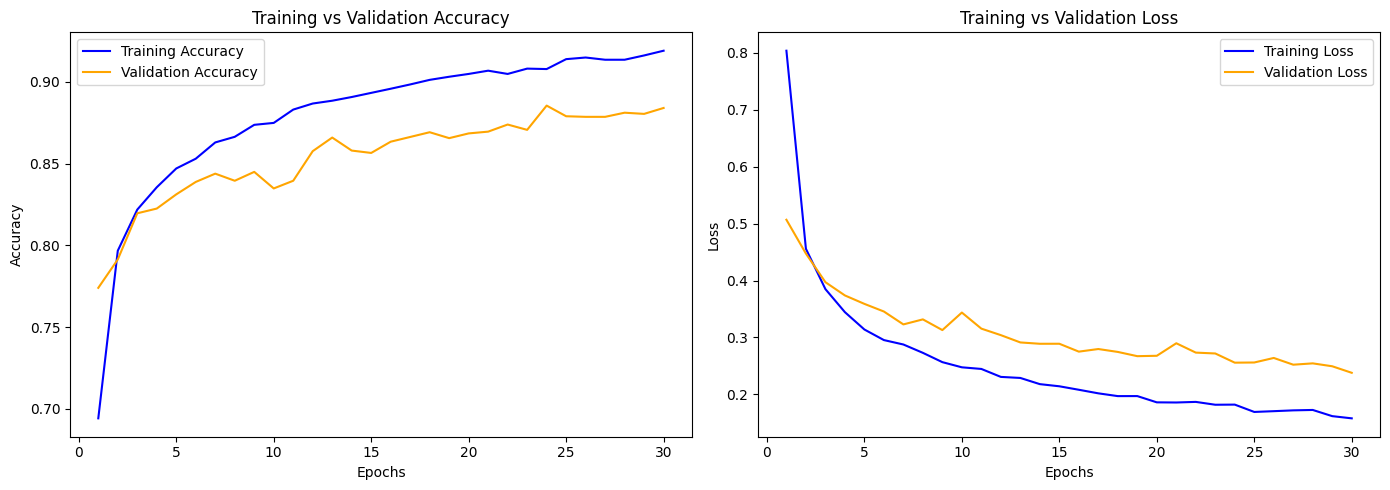

In [14]:
import matplotlib.pyplot as plt
import json

def save_and_plot_history(train_acc, val_acc, train_loss, val_loss, save_filename='training_history.json', plot_epochs=30):
    

    history_data = {
        'train_acc': train_acc,
        'val_acc': val_acc,
        'train_loss': train_loss,
        'val_loss': val_loss
    }
    
    with open(save_filename, 'w') as f:
        json.dump(history_data, f)
    print(f"Full training history saved to {save_filename}")

   
    t_acc_plot = train_acc[:plot_epochs]
    v_acc_plot = val_acc[:plot_epochs]
    t_loss_plot = train_loss[:plot_epochs]
    v_loss_plot = val_loss[:plot_epochs]

    epochs_range = range(1, len(t_acc_plot) + 1)

    plt.figure(figsize=(14, 5))

    # Accuracy Plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, t_acc_plot, label='Training Accuracy', color='blue')
    plt.plot(epochs_range, v_acc_plot, label='Validation Accuracy', color='orange')
    plt.title(f'Training vs Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    # loc='best' automatically finds the empty spot in the plot
    plt.legend(loc='best') 
    

    # Loss Plot 
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, t_loss_plot, label='Training Loss', color='blue')
    plt.plot(epochs_range, v_loss_plot, label='Validation Loss', color='orange')
    plt.title(f'Training vs Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    
    plt.legend(loc='best')
    

    plt.tight_layout()
    plt.show()


save_and_plot_history(train_acc_list, val_acc_list, train_loss_list, val_loss_list, plot_epochs=30)

In [ ]:
# Initializing the architecture
model_best = CustomEnsemble(
    num_classes=number_of_classes,
    path_eff='efficientNetB0_freezed.pth', 
    path_vgg='vgg16_freezed.pth',
    path_vit='vision_transformer_freezed.pth',
    device=device
).to(device)

# Load the best weights from your training session
checkpoint = torch.load('custom_ensemble_model_without_norm.pth', map_location=device)
model_best.load_state_dict(checkpoint['model_state_dict'])
model_best.eval()

print(f"Loaded model from Epoch {checkpoint['epoch']} with Loss {checkpoint['loss']:.4f}")

def evaluate_with_tta(model, loader, device):
    model.eval()
    
    # Standard Metrics
    correct_standard = 0
    total = 0
    
    # TTA Metrics
    correct_tta = 0
    
    print("Running Evaluation with Test Time Augmentation (TTA)...")
    
    with torch.no_grad():
        for images, labels in tqdm(loader, desc="TTA Evaluation"):
            images, labels = images.to(device), labels.to(device)
            
            # Prediction: Original Image
            outputs_orig = model(images)
            probs_orig = F.softmax(outputs_orig, dim=1) # Convert logits to probabilities
            
            # Prediction : Horizontally Flipped Image 

            images_flipped = torch.flip(images, dims=[3]) 
            outputs_flip = model(images_flipped)
            probs_flip = F.softmax(outputs_flip, dim=1)
            

            # Averaging Original + Flipped
            avg_probs = (probs_orig + probs_flip) / 2 
            

            
            # Standard Accuracy for Original images
            _, preds_standard = torch.max(probs_orig, 1)
            correct_standard += torch.sum(preds_standard == labels).item()
            
            # TTA Accuracy 
            _, preds_tta = torch.max(avg_probs, 1)
            correct_tta += torch.sum(preds_tta == labels).item()
            
            total += labels.size(0)

    # Calculating final percentages
    acc_standard = correct_standard / total
    acc_tta = correct_tta / total
    
    print(f"\nResults:")
    print(f"Standard Accuracy: {acc_standard:.4f} ({acc_standard*100:.2f}%)")
    print(f"TTA Accuracy:      {acc_tta:.4f} ({acc_tta*100:.2f}%)")
    
    improvement = acc_tta - acc_standard
    print(f"Improvement:       {improvement*100:+.2f}%")
    
    return acc_tta


tta_accuracy = evaluate_with_tta(model_best, val_loader, device)

Loaded model from Epoch 30 with Loss 0.2379
Running Evaluation with Test Time Augmentation (TTA)...


TTA Evaluation: 100%|██████████| 87/87 [01:13<00:00,  1.19it/s]


Results:
Standard Accuracy: 0.8841 (88.41%)
TTA Accuracy:      0.8899 (88.99%)
Improvement:       +0.58%


In [3]:
class CustomEnsemble(nn.Module):
    def __init__(self, num_classes, path_eff, path_vgg, path_vit, device='cuda'):
        super(CustomEnsemble, self).__init__()
        
        # Loading EfficientNetB0 
        self.efficientNet = models.efficientnet_b0(weights=None)
        # recreating the exact structure used in training before loading weights
        eff_in_features = self.efficientNet.classifier[1].in_features
        self.efficientNet.classifier[1] = nn.Linear(eff_in_features, num_classes)
        
        
        checkpoint_eff = torch.load(path_eff, map_location=device)
        self.efficientNet.load_state_dict(checkpoint_eff['model_state_dict'])
        
        # Removing the head to output raw features 
        self.efficientNet.classifier = nn.Identity()
        
        # Loading VGG16
        self.vgg16 = models.vgg16(weights=None)
        
        vgg_in_features = self.vgg16.classifier[6].in_features
        self.vgg16.classifier[6] = nn.Linear(vgg_in_features, num_classes)
        
        
        checkpoint_vgg = torch.load(path_vgg, map_location=device)
        self.vgg16.load_state_dict(checkpoint_vgg['model_state_dict'])
        
        self.vgg16.classifier[6] = nn.Identity()

        # Loading Vision Transformer
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=False)
      
        vit_in_features = self.vit.head.in_features
        self.vit.head = nn.Linear(vit_in_features, num_classes)
        
       
        checkpoint_vit = torch.load(path_vit, map_location=device)
        self.vit.load_state_dict(checkpoint_vit['model_state_dict'])
        
    
        self.vit.head = nn.Identity()

        
        # freezing everything
        for model in [self.efficientNet, self.vgg16, self.vit]:
            for param in model.parameters():
                param.requires_grad = False
 
        # Unfreezing  last 2 blocks for eficientNet
        for param in self.efficientNet.features[7:].parameters():
            param.requires_grad = True

        # Unfreezing last 6 block of convulotions for vgg
        for param in self.vgg16.features[24:].parameters():
            param.requires_grad = True
            
        # Unfreezing the last block and then normalization of the layers
        for param in self.vit.blocks[-1].parameters():
            param.requires_grad = True


        # Custom Fusion Head
        total_features = eff_in_features + vgg_in_features + vit_in_features
        
        self.fusion_head = nn.Sequential(
            nn.Linear(total_features, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        f1 = self.efficientNet(x)
        f2 = self.vgg16(x)
        f3 = self.vit(x)
        
        concatenated_features = torch.cat((f1, f2, f3), dim=1)
        output = self.fusion_head(concatenated_features)
        return output



Test Evaluation along with TTA: 100%|██████████| 87/87 [01:08<00:00,  1.27it/s]



Test Accuracy (with TTA): 0.8899
Cohen's Kappa: 0.8716
MCC: 0.8718
Macro Sensitivity (Recall): 0.9236
Macro Specificity: 0.9872

Per-Class Performance:
  Color Fundus     Precision: 0.7680  Recall: 0.9320  F1: 0.8421
  Diabetic Retinopathy  Precision: 0.9893  Recall: 0.9470  F1: 0.9677
  Disc Edema       Precision: 0.9078  Recall: 0.9846  F1: 0.9446
  Glaucoma         Precision: 0.8073  Recall: 0.8139  F1: 0.8106
  Healthy          Precision: 0.9007  Recall: 0.8176  F1: 0.8571
  Macular Scar     Precision: 0.8251  Recall: 0.8602  F1: 0.8423
  Myopia           Precision: 0.8831  Recall: 0.8877  F1: 0.8854
  Pterygium        Precision: 1.0000  Recall: 1.0000  F1: 1.0000
  Retinal Detachment  Precision: 0.9845  Recall: 1.0000  F1: 0.9922
  Retinitis Pigmentosa  Precision: 0.9156  Recall: 0.9930  F1: 0.9527

Macro F1-score: 0.9095
Weighted F1: 0.8901
Weighted AUC: 0.9901
Macro AUC (OvR): 0.9934
Weighted AUC (OvR): 0.9901

Classification Report:
                       precision    recall  

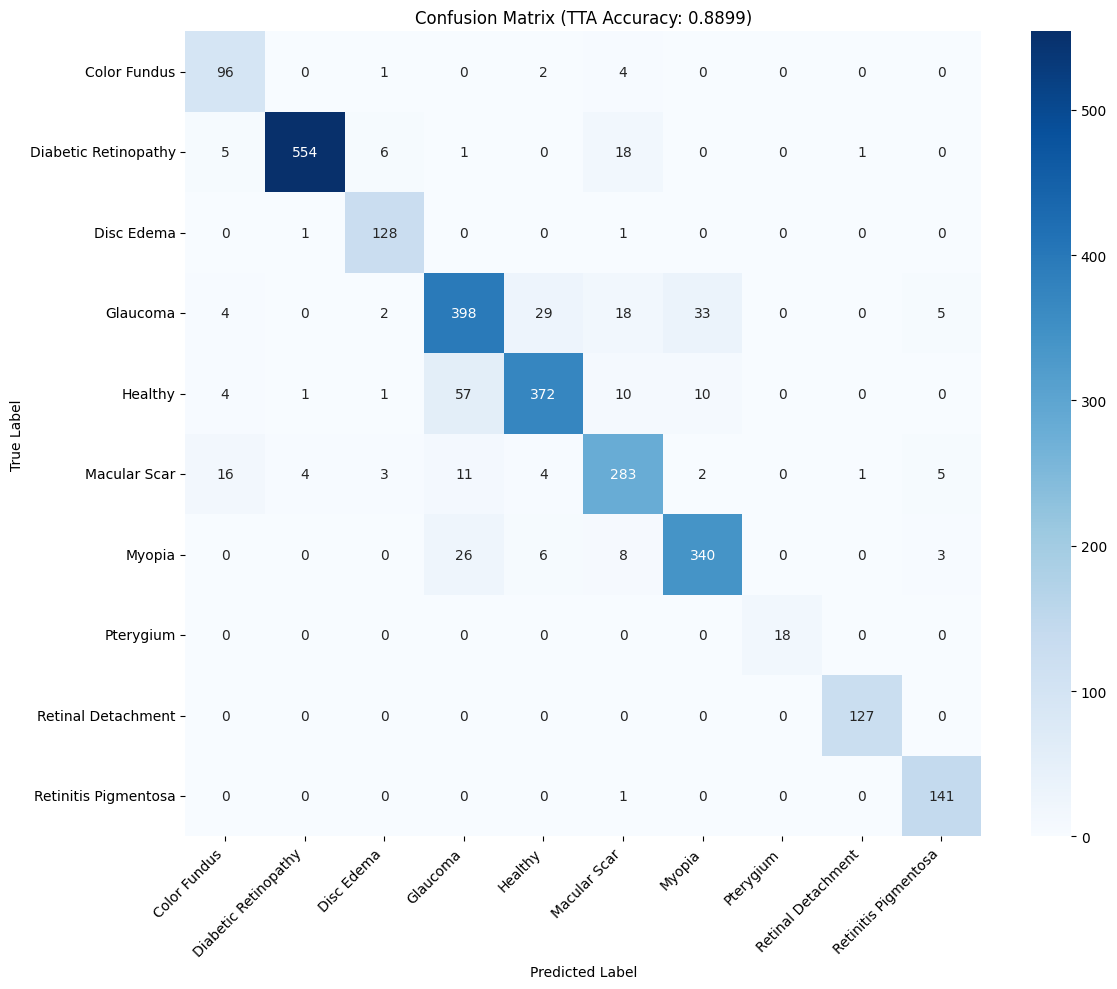

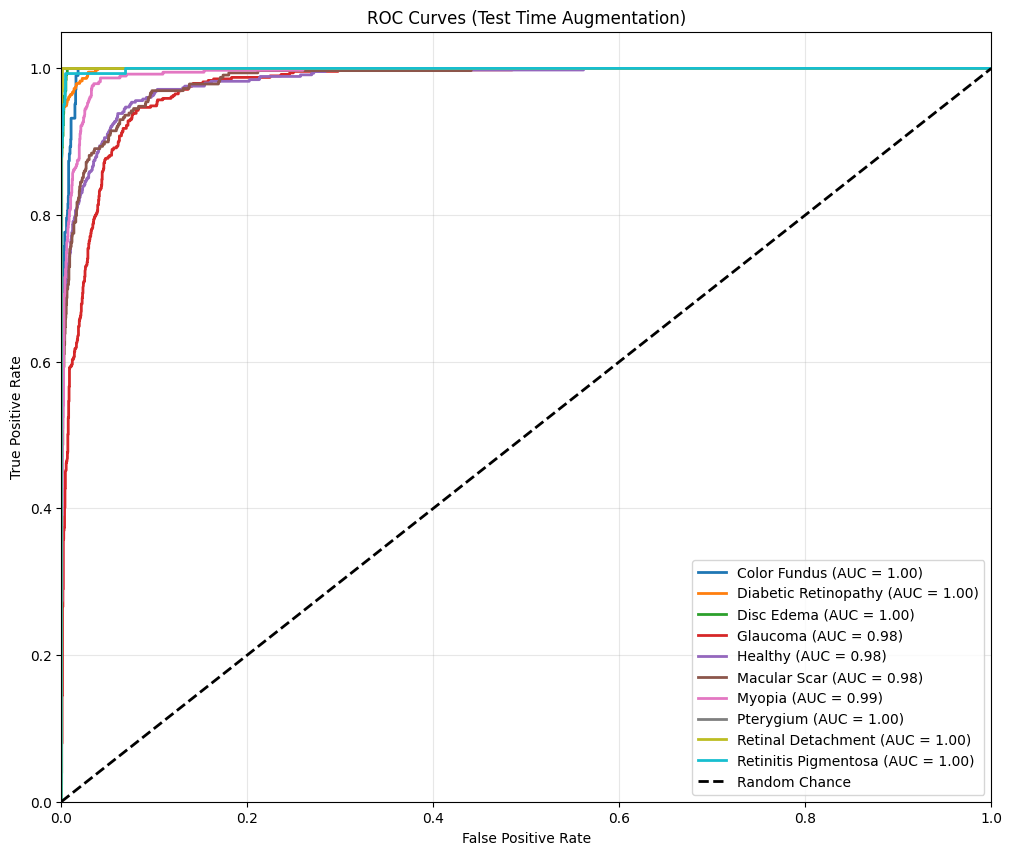

{'accuracy': 0.8898949655921767,
 'kappa': 0.8715901773547616,
 'mcc': 0.8718178317727877,
 'weighted_f1': 0.8900856591957964,
 'macro_f1': np.float64(0.9094742561810705),
 'per_class_f1': array([0.84210526, 0.96768559, 0.94464945, 0.81059063, 0.85714286,
        0.8422619 , 0.88541667, 1.        , 0.9921875 , 0.9527027 ]),
 'confusion_matrix': array([[ 96,   0,   1,   0,   2,   4,   0,   0,   0,   0],
        [  5, 554,   6,   1,   0,  18,   0,   0,   1,   0],
        [  0,   1, 128,   0,   0,   1,   0,   0,   0,   0],
        [  4,   0,   2, 398,  29,  18,  33,   0,   0,   5],
        [  4,   1,   1,  57, 372,  10,  10,   0,   0,   0],
        [ 16,   4,   3,  11,   4, 283,   2,   0,   1,   5],
        [  0,   0,   0,  26,   6,   8, 340,   0,   0,   3],
        [  0,   0,   0,   0,   0,   0,   0,  18,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0, 127,   0],
        [  0,   0,   0,   0,   0,   1,   0,   0,   0, 141]]),
 'predictions': array([5, 0, 8, ..., 1, 1, 9], shape

In [ ]:
def evaluate_model(model, data_loader, device, num_classes, class_names):
    model.eval()
    
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for images, labels in tqdm(data_loader, desc="Test Evaluation along with TTA"):
            images, labels = images.to(device), labels.to(device)
         
            # Prediction on Original Image
            outputs_orig = model(images)
            probs_orig = F.softmax(outputs_orig, dim=1)
            
            # Prediction on Horizontally Flipped Image
            images_flipped = torch.flip(images, dims=[3]) 
            outputs_flip = model(images_flipped)
            probs_flip = F.softmax(outputs_flip, dim=1)
            
            # Average Probabilities 
            avg_probs = (probs_orig + probs_flip) / 2 
            
            # Getting the final prediction from the averaged probabilities
            _, preds = torch.max(avg_probs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(avg_probs.cpu().numpy())
    
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)
    
    # Overall accuracy
    accuracy = accuracy_score(all_labels, all_preds)

    # Precision, recall, f1 per class
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average=None)

    # Macro f1
    macro_f1 = f1.mean()

    # Weighted metrics
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')

    # Cohen-kappa
    kappa = cohen_kappa_score(all_labels, all_preds)

    # MCC
    mcc = matthews_corrcoef(all_labels, all_preds)

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)

    sensitivity = sensitivity_score(all_labels, all_preds, average='macro')
    specificity = specificity_score(all_labels, all_preds, average='macro')

    # AUC (Weighted OVR)
    
    auc_ovr = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='weighted')
    
    # Macro‑average AUC 
    auc_macro = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='macro')

    # Weighted AUC 
    auc_weighted = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='weighted')

    # Classification report
    classif_report = classification_report(all_labels, all_preds, target_names=class_names)

    # Print Metrics
    print(f"\nTest Accuracy (with TTA): {accuracy:.4f}")
    print(f"Cohen's Kappa: {kappa:.4f}")
    print(f"MCC: {mcc:.4f}")
    print(f"Macro Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Macro Specificity: {specificity:.4f}")
    print("\nPer-Class Performance:")
    for i, name in enumerate(class_names):
        print(f"  {name:15s}  Precision: {precision[i]:.4f}  Recall: {recall[i]:.4f}  F1: {f1[i]:.4f}")
    print(f"\nMacro F1-score: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print(f"Weighted AUC: {auc_ovr:.4f}")
    print(f"Macro AUC (OvR): {auc_macro:.4f}")
    print(f"Weighted AUC (OvR): {auc_weighted:.4f}")
    print("\nClassification Report:\n", classif_report)
    print("Detailed classification report")
    print(classification_report(all_labels, all_preds, target_names=class_names))


    # Plot Confusion Matrix
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix (TTA Accuracy: {accuracy:.4f})')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # Plot ROC Curves
    y_true_bin = label_binarize(all_labels, classes=range(num_classes))
    
    plt.figure(figsize=(12, 10))
    colors = plt.cm.tab10(np.linspace(0, 1, num_classes))

    for i, color in zip(range(num_classes), colors):
        if np.sum(all_labels == i) > 0:
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], all_probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, color=color, lw=2, 
                     label=f'{class_names[i]} (AUC = {roc_auc:.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Chance')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves (Test Time Augmentation)')
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()

    metrics = {
        'accuracy': accuracy,
        'kappa': kappa,
        'mcc': mcc,
        'weighted_f1': weighted_f1,
        'macro_f1': macro_f1,
        'per_class_f1': f1,
        'confusion_matrix': cm,
        'predictions': all_preds,
        'labels': all_labels,
        'probabilities': all_probs,
        'auc_ovr': auc_ovr
    }
    return metrics


model = CustomEnsemble(
    num_classes=number_of_classes,
    path_eff='efficientNetB0_freezed.pth',
    path_vgg='vgg16_freezed.pth',
    path_vit='vision_transformer_freezed.pth',
    device=device
).to(device)

checkpoint = torch.load('custom_ensemble_model_without_norm.pth', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

evaluate_model(model, val_loader, device, number_of_classes, class_names)

## Grad-CAM

Loaded weights from custom_ensemble_model_without_norm.pth


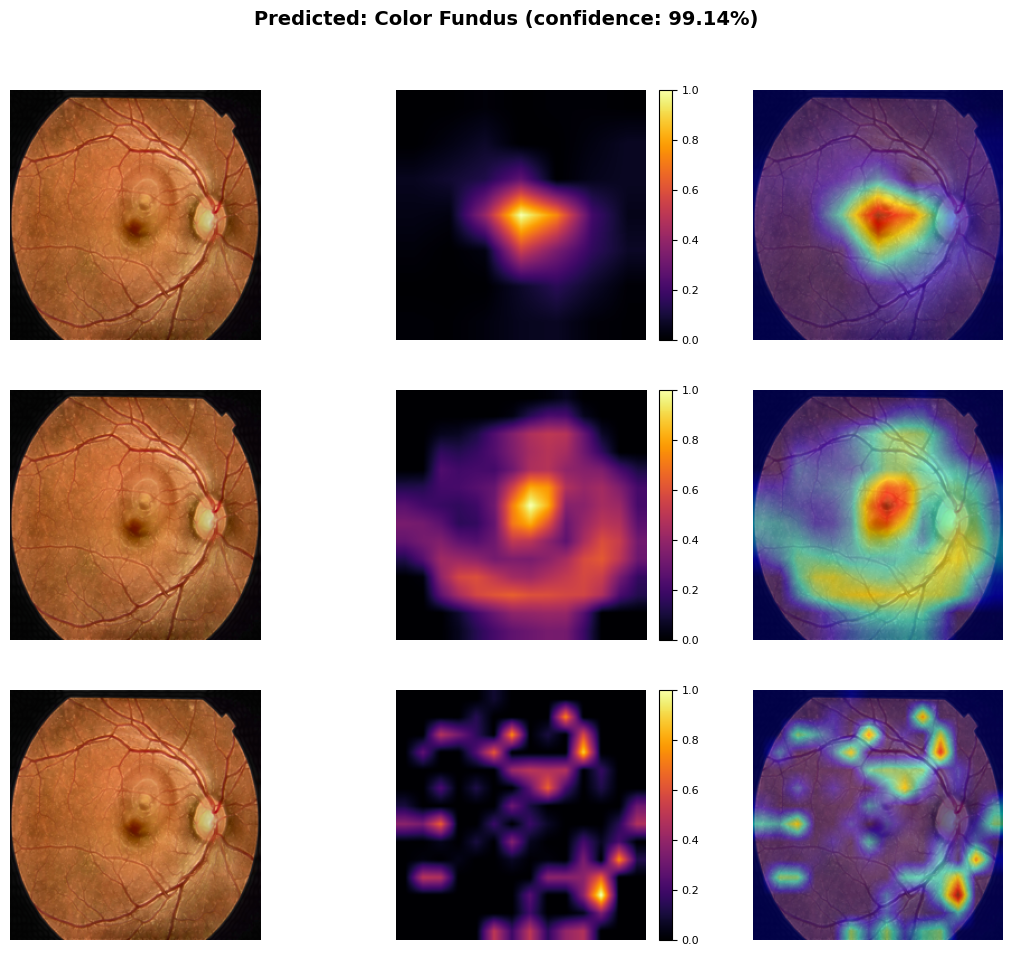

In [ ]:
def reshape_transform_vit(tensor):
  
    height = 14
    width = 14
    
    # Reshape to [batch, 14, 14, 768]
    result = tensor[:, 1:, :].reshape(tensor.size(0), height, width, tensor.size(2))

    # Permute to [batch, 768, 14, 14]
    result = result.transpose(2, 3).transpose(1, 2)
    return result

def visualize_ensemble_gradcam_improved(model, image_path, transform, class_names, device):
    model.eval()
    
   
    pil_img = Image.open(image_path).convert('RGB')

    vis_img_pil = pil_img.resize((224, 224))
    img_vis = np.array(vis_img_pil, dtype=np.float32) / 255.0 

    input_tensor = transform(pil_img).unsqueeze(0).to(device)
    

    
    # Get Prediction 
    with torch.no_grad():
        logits = model(input_tensor)
        probs = F.softmax(logits, dim=1)
        pred_class_idx = torch.argmax(probs, dim=1).item()
        pred_prob = probs[0, pred_class_idx].item()
        pred_label = class_names[pred_class_idx]

    # We want to see what parts of the image contribute to the Predicted Class
    targets = [ClassifierOutputTarget(pred_class_idx)]

    
    
    # EfficientNet Grad-CAM
    # Target the last convolutional block in the features
    target_layers_eff = [model.efficientNet.features[-1]]
    cam_eff_obj = GradCAM(model=model, target_layers=target_layers_eff)
    grayscale_cam_eff = cam_eff_obj(input_tensor=input_tensor, targets=targets)[0, :]
    
    #  VGG16 Grad-CAM
    # Target the last CONV layer. In VGG16 features:
    target_layers_vgg = [model.vgg16.features[-3]] 
    cam_vgg_obj = GradCAM(model=model, target_layers=target_layers_vgg)
    grayscale_cam_vgg = cam_vgg_obj(input_tensor=input_tensor, targets=targets)[0, :]
    
    # Vision Transformer Grad-CAM
    # Target the last LayerNorm before the head (standard for ViT)
    target_layers_vit = [model.vit.blocks[-1].norm1]
    cam_vit_obj = GradCAM(model=model, target_layers=target_layers_vit, reshape_transform=reshape_transform_vit)
    grayscale_cam_vit = cam_vit_obj(input_tensor=input_tensor, targets=targets)[0, :]

 
    vis_eff = show_cam_on_image(img_vis, grayscale_cam_eff, use_rgb=True)
    vis_vgg = show_cam_on_image(img_vis, grayscale_cam_vgg, use_rgb=True)
    vis_vit = show_cam_on_image(img_vis, grayscale_cam_vit, use_rgb=True)

    
    plt.rcParams.update({'font.size': 12, 'font.family': 'sans-serif'})
    fig, axes = plt.subplots(3, 3, figsize=(12, 10))
    fig.subplots_adjust(left=0.05, right=0.95, top=0.90, bottom=0.05, wspace=0.1, hspace=0.2)
    
   
    row_labels = ['EfficientNet', 'VGG16', 'ViT']
    
   
    data_rows = [
        (img_vis, grayscale_cam_eff, vis_eff, "EfficientNet"),
        (img_vis, grayscale_cam_vgg, vis_vgg, "VGG16"),
        (img_vis, grayscale_cam_vit, vis_vit, "Vision Transformer")
    ]
    
    for i, (orig, hm, overlay, label) in enumerate(data_rows):
        # Original
        axes[i, 0].imshow(orig)
        axes[i, 0].axis('off')
        # if i == 0: axes[i, 0].set_title("Original Image", fontweight='bold')
        
 

        # Heatmap
        im = axes[i, 1].imshow(hm, cmap='inferno', vmin=0, vmax=1)
        axes[i, 1].axis('off')
        # if i == 0: axes[i, 1].set_title("Grad-CAM Heatmap", fontweight='bold')
        
        # Colorbar for heatmap
        cbar = fig.colorbar(im, ax=axes[i, 1], fraction=0.046, pad=0.04)
        cbar.ax.tick_params(labelsize=8)

        # Overlay
        axes[i, 2].imshow(overlay)
        axes[i, 2].axis('off')
        # if i == 0: axes[i, 2].set_title("Overlay", fontweight='bold')

    
    fig.suptitle(f"Predicted: {pred_label} (confidence: {pred_prob:.2%})", 
                 fontsize=14, fontweight='bold', y=0.98)
    
    plt.show()



model = CustomEnsemble(
    num_classes=number_of_classes,
    path_eff='efficientNetB0_freezed.pth',
    path_vgg='vgg16_freezed.pth',
    path_vit='vision_transformer_freezed.pth',
    device=device
).to(device)


weights_path = 'custom_ensemble_model_without_norm.pth' 
if os.path.exists(weights_path):
    checkpoint = torch.load(weights_path, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"Loaded weights from {weights_path}")
else:
    print(f"Warning: {weights_path} not found. Using random weights.")


img_path = r"D:\GG\Datasets\Eye Disease Image Dataset\Fourier_Enhanced_Dataset\Color Fundus\CSCR105.jpg"

if os.path.exists(img_path):
    visualize_ensemble_gradcam_improved(model, img_path, val_test_transforms, class_names, device)
else:
    print(f"Image not found at {img_path}")

Test Evaluation along with TTA: 100%|██████████| 87/87 [01:22<00:00,  1.05it/s]



Test Accuracy (with TTA): 0.8899
Cohen's Kappa: 0.8716
MCC: 0.8718
Macro Sensitivity (Recall): 0.9236
Macro Specificity: 0.9872

Per-Class Performance:
  Color Fundus     Precision: 0.7680  Recall: 0.9320  F1: 0.8421
  Diabetic Retinopathy  Precision: 0.9893  Recall: 0.9470  F1: 0.9677
  Disc Edema       Precision: 0.9078  Recall: 0.9846  F1: 0.9446
  Glaucoma         Precision: 0.8073  Recall: 0.8139  F1: 0.8106
  Healthy          Precision: 0.9007  Recall: 0.8176  F1: 0.8571
  Macular Scar     Precision: 0.8251  Recall: 0.8602  F1: 0.8423
  Myopia           Precision: 0.8831  Recall: 0.8877  F1: 0.8854
  Pterygium        Precision: 1.0000  Recall: 1.0000  F1: 1.0000
  Retinal Detachment  Precision: 0.9845  Recall: 1.0000  F1: 0.9922
  Retinitis Pigmentosa  Precision: 0.9156  Recall: 0.9930  F1: 0.9527

Macro F1-score: 0.9095
Weighted F1: 0.8901
Weighted AUC: 0.9901
Macro AUC (OvR): 0.9934
Weighted AUC (OvR): 0.9901

Classification Report:
                       precision    recall  

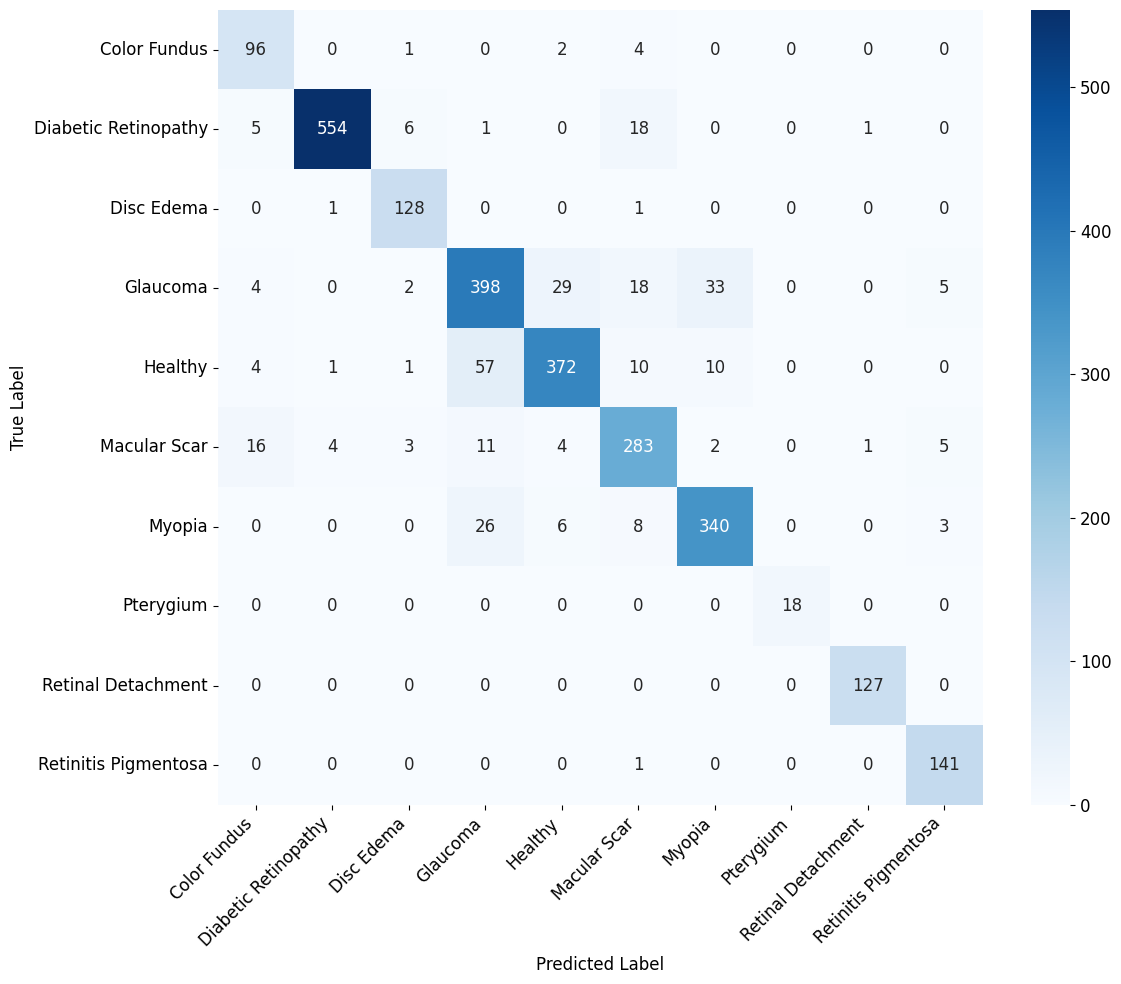

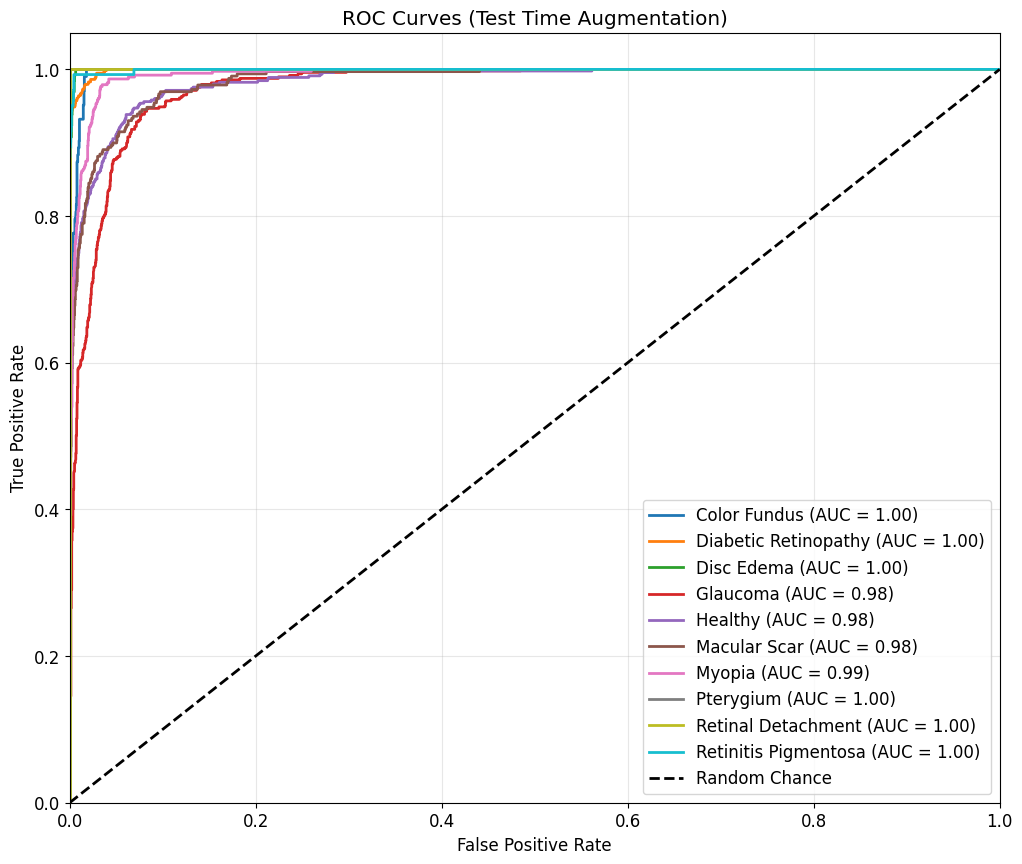

{'accuracy': 0.8898949655921767,
 'kappa': 0.8715901773547616,
 'mcc': 0.8718178317727877,
 'weighted_f1': 0.8900856591957964,
 'macro_f1': np.float64(0.9094742561810705),
 'per_class_f1': array([0.84210526, 0.96768559, 0.94464945, 0.81059063, 0.85714286,
        0.8422619 , 0.88541667, 1.        , 0.9921875 , 0.9527027 ]),
 'confusion_matrix': array([[ 96,   0,   1,   0,   2,   4,   0,   0,   0,   0],
        [  5, 554,   6,   1,   0,  18,   0,   0,   1,   0],
        [  0,   1, 128,   0,   0,   1,   0,   0,   0,   0],
        [  4,   0,   2, 398,  29,  18,  33,   0,   0,   5],
        [  4,   1,   1,  57, 372,  10,  10,   0,   0,   0],
        [ 16,   4,   3,  11,   4, 283,   2,   0,   1,   5],
        [  0,   0,   0,  26,   6,   8, 340,   0,   0,   3],
        [  0,   0,   0,   0,   0,   0,   0,  18,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0, 127,   0],
        [  0,   0,   0,   0,   0,   1,   0,   0,   0, 141]]),
 'predictions': array([5, 0, 8, ..., 1, 1, 9], shape

In [ ]:
def evaluate_model(model, data_loader, device, num_classes, class_names):
    model.eval()
    
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for images, labels in tqdm(data_loader, desc="Test Evaluation along with TTA"):
            images, labels = images.to(device), labels.to(device)
         
            # Prediction on Original Image
            outputs_orig = model(images)
            probs_orig = F.softmax(outputs_orig, dim=1)
            
            # Prediction on Horizontally Flipped Image
            images_flipped = torch.flip(images, dims=[3]) 
            outputs_flip = model(images_flipped)
            probs_flip = F.softmax(outputs_flip, dim=1)
            
            # Average Probabilities 
            avg_probs = (probs_orig + probs_flip) / 2 
            
            # Getting the final prediction from the averaged probabilities
            _, preds = torch.max(avg_probs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(avg_probs.cpu().numpy())
    
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)
    
    # Overall accuracy
    accuracy = accuracy_score(all_labels, all_preds)

    # Precision, recall, f1 per class
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average=None)

    # Macro f1
    macro_f1 = f1.mean()

    # Weighted metrics
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')

    # Cohen-kappa
    kappa = cohen_kappa_score(all_labels, all_preds)

    # MCC
    mcc = matthews_corrcoef(all_labels, all_preds)

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)

    sensitivity = sensitivity_score(all_labels, all_preds, average='macro')
    specificity = specificity_score(all_labels, all_preds, average='macro')

    # AUC (Weighted OVR)
    
    auc_ovr = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='weighted')
    
    # Macro‑average AUC 
    auc_macro = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='macro')

    # Weighted AUC 
    auc_weighted = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='weighted')

    # Classification report
    classif_report = classification_report(all_labels, all_preds, target_names=class_names)

    # Print Metrics
    print(f"\nTest Accuracy (with TTA): {accuracy:.4f}")
    print(f"Cohen's Kappa: {kappa:.4f}")
    print(f"MCC: {mcc:.4f}")
    print(f"Macro Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Macro Specificity: {specificity:.4f}")
    print("\nPer-Class Performance:")
    for i, name in enumerate(class_names):
        print(f"  {name:15s}  Precision: {precision[i]:.4f}  Recall: {recall[i]:.4f}  F1: {f1[i]:.4f}")
    print(f"\nMacro F1-score: {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print(f"Weighted AUC: {auc_ovr:.4f}")
    print(f"Macro AUC (OvR): {auc_macro:.4f}")
    print(f"Weighted AUC (OvR): {auc_weighted:.4f}")
    print("\nClassification Report:\n", classif_report)
    print("Detailed classification report")
    print(classification_report(all_labels, all_preds, target_names=class_names))


    # Plot Confusion Matrix
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # Plot ROC Curves
    y_true_bin = label_binarize(all_labels, classes=range(num_classes))
    
    plt.figure(figsize=(12, 10))
    colors = plt.cm.tab10(np.linspace(0, 1, num_classes))

    for i, color in zip(range(num_classes), colors):
        if np.sum(all_labels == i) > 0:
            fpr, tpr, _ = roc_curve(y_true_bin[:, i], all_probs[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, color=color, lw=2, 
                     label=f'{class_names[i]} (AUC = {roc_auc:.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Chance')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    # plt.title('ROC Curves (Test Time Augmentation)')
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.show()

    metrics = {
        'accuracy': accuracy,
        'kappa': kappa,
        'mcc': mcc,
        'weighted_f1': weighted_f1,
        'macro_f1': macro_f1,
        'per_class_f1': f1,
        'confusion_matrix': cm,
        'predictions': all_preds,
        'labels': all_labels,
        'probabilities': all_probs,
        'auc_ovr': auc_ovr
    }
    return metrics


model = CustomEnsemble(
    num_classes=number_of_classes,
    path_eff='efficientNetB0_freezed.pth',
    path_vgg='vgg16_freezed.pth',
    path_vit='vision_transformer_freezed.pth',
    device=device
).to(device)

checkpoint = torch.load('custom_ensemble_model_without_norm.pth', map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

evaluate_model(model, val_loader, device, number_of_classes, class_names)